In [1]:
import xarray as xr
import cartopy.crs as ccrs
import numpy as np
from pystormtracker.preprocessing import SHTFilter
import sys
import os
from pathlib import Path
import pystormtracker as pst

module_dir = (Path.cwd() / ".."/".." / "algorithms").resolve()
sys.path.insert(0,str(module_dir))

import validation as val
import processing as pro
import helpers
import statistics_on_tracks as stats
from configs import *
from plotting import *

In [2]:
colors = setup_plotting()

In [3]:


tracks_for_test = pst.load_tracks('/Users/annasophiamaxen/Desktop/PYTHON/master_thesis/trackjson/20152016_DJF_0p25_vo_filtered.trackjson')

track_vars_path = '/Users/annasophiamaxen/Desktop/PYTHON/master_thesis/reanalysis_data/ERA5/ERA5_single_levels/20152016_DJF_sl_0p25.nc'

track_vars = xr.open_dataset(track_vars_path)

In [4]:
kinematics = stats.sample_along_tracks(tracks_for_test, track_vars, radius_km=300)

/Users/annasophiamaxen/Desktop/PYTHON/master_thesis/algorithms/statistics_on_tracks.py:233: UserWarning: 2 points of 2 tracks are (within 300 km) outside the single-level area [90, -120, 10, 40]; their single-level samples are NaN
  warnings.warn(f"{int((~inside).sum())} points of {n_tracks} tracks are (within {radius} km) outside "


## Sample at several radii
Every track point is sampled once per radius. Points whose circle leaves the single-level area at the
largest radius are dropped at **all** radii, so every radius is compared on the same points.

In [5]:
import warnings
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

RADII = [100, 200, 300, 400, 500, 750]   # km
REF_RADIUS = 500                                # previous default, marked in the plots

runs = []
for r in RADII:
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message=".*outside the single-level area.*")
        runs.append(stats.sample_along_tracks(tracks_for_test, track_vars, radius_km=r).assign(radius_km=r))
sampled_all = pd.concat(runs, ignore_index=True)

# same points at every radius
in_all = sampled_all.loc[sampled_all["radius_km"] == max(RADII)].set_index(["track_id", "time"])["inside_area"]
sampled = sampled_all.join(in_all.rename("in_all"), on=["track_id", "time"])
sampled = sampled[sampled["in_all"]].drop(columns="in_all")
n_pts = sampled.groupby(["track_id", "time"]).ngroups
print(f"{n_pts} of {len(runs[0])} points inside the area at every radius, {sampled['track_id'].nunique()} tracks")

1864 of 1906 points inside the area at every radius, 124 tracks


In [6]:
VARS = {  # column: (label, units, lifetime extreme per track)
    "msl_min":     ("MSLP min",       "hPa",        "min"),
    "ws10_max":    ("10 m wind max",  "m s$^{-1}$", "max"),
    "ws10_mean":   ("10 m wind mean", "m s$^{-1}$", "max"),
    "gust10_max":  ("10 m gust max",  "m s$^{-1}$", "max"),
    "gust10_mean": ("10 m gust mean", "m s$^{-1}$", "max"),
}
# radius is an ordered magnitude -> one sequential hue, light (small) to dark (large)
RCOL = dict(zip(RADII, plt.get_cmap("Blues")(np.linspace(0.35, 1.0, len(RADII)))))
LINE = "#2b6cb0"

# lifetime extreme of every track (min pressure, max wind), one row per track and radius
per_track = sampled.groupby(["radius_km", "track_id"]).agg({c: v[2] for c, v in VARS.items()}).reset_index()

def plain_axis(ax, axis="y"):
    """Full numbers on the axis (no '1e3' offset)."""
    fmt = ScalarFormatter(useOffset=False)
    fmt.set_scientific(False)
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)

def legend_outside(ax):
    ax.legend(title="Radius", fontsize=13, title_fontsize=14, loc="center left", bbox_to_anchor=(1.02, 0.5))

### Median and interquartile range vs radius
Top: every track point. Bottom: lifetime extreme of each track (lowest MSLP, highest wind), i.e. what enters the per-track statistics.

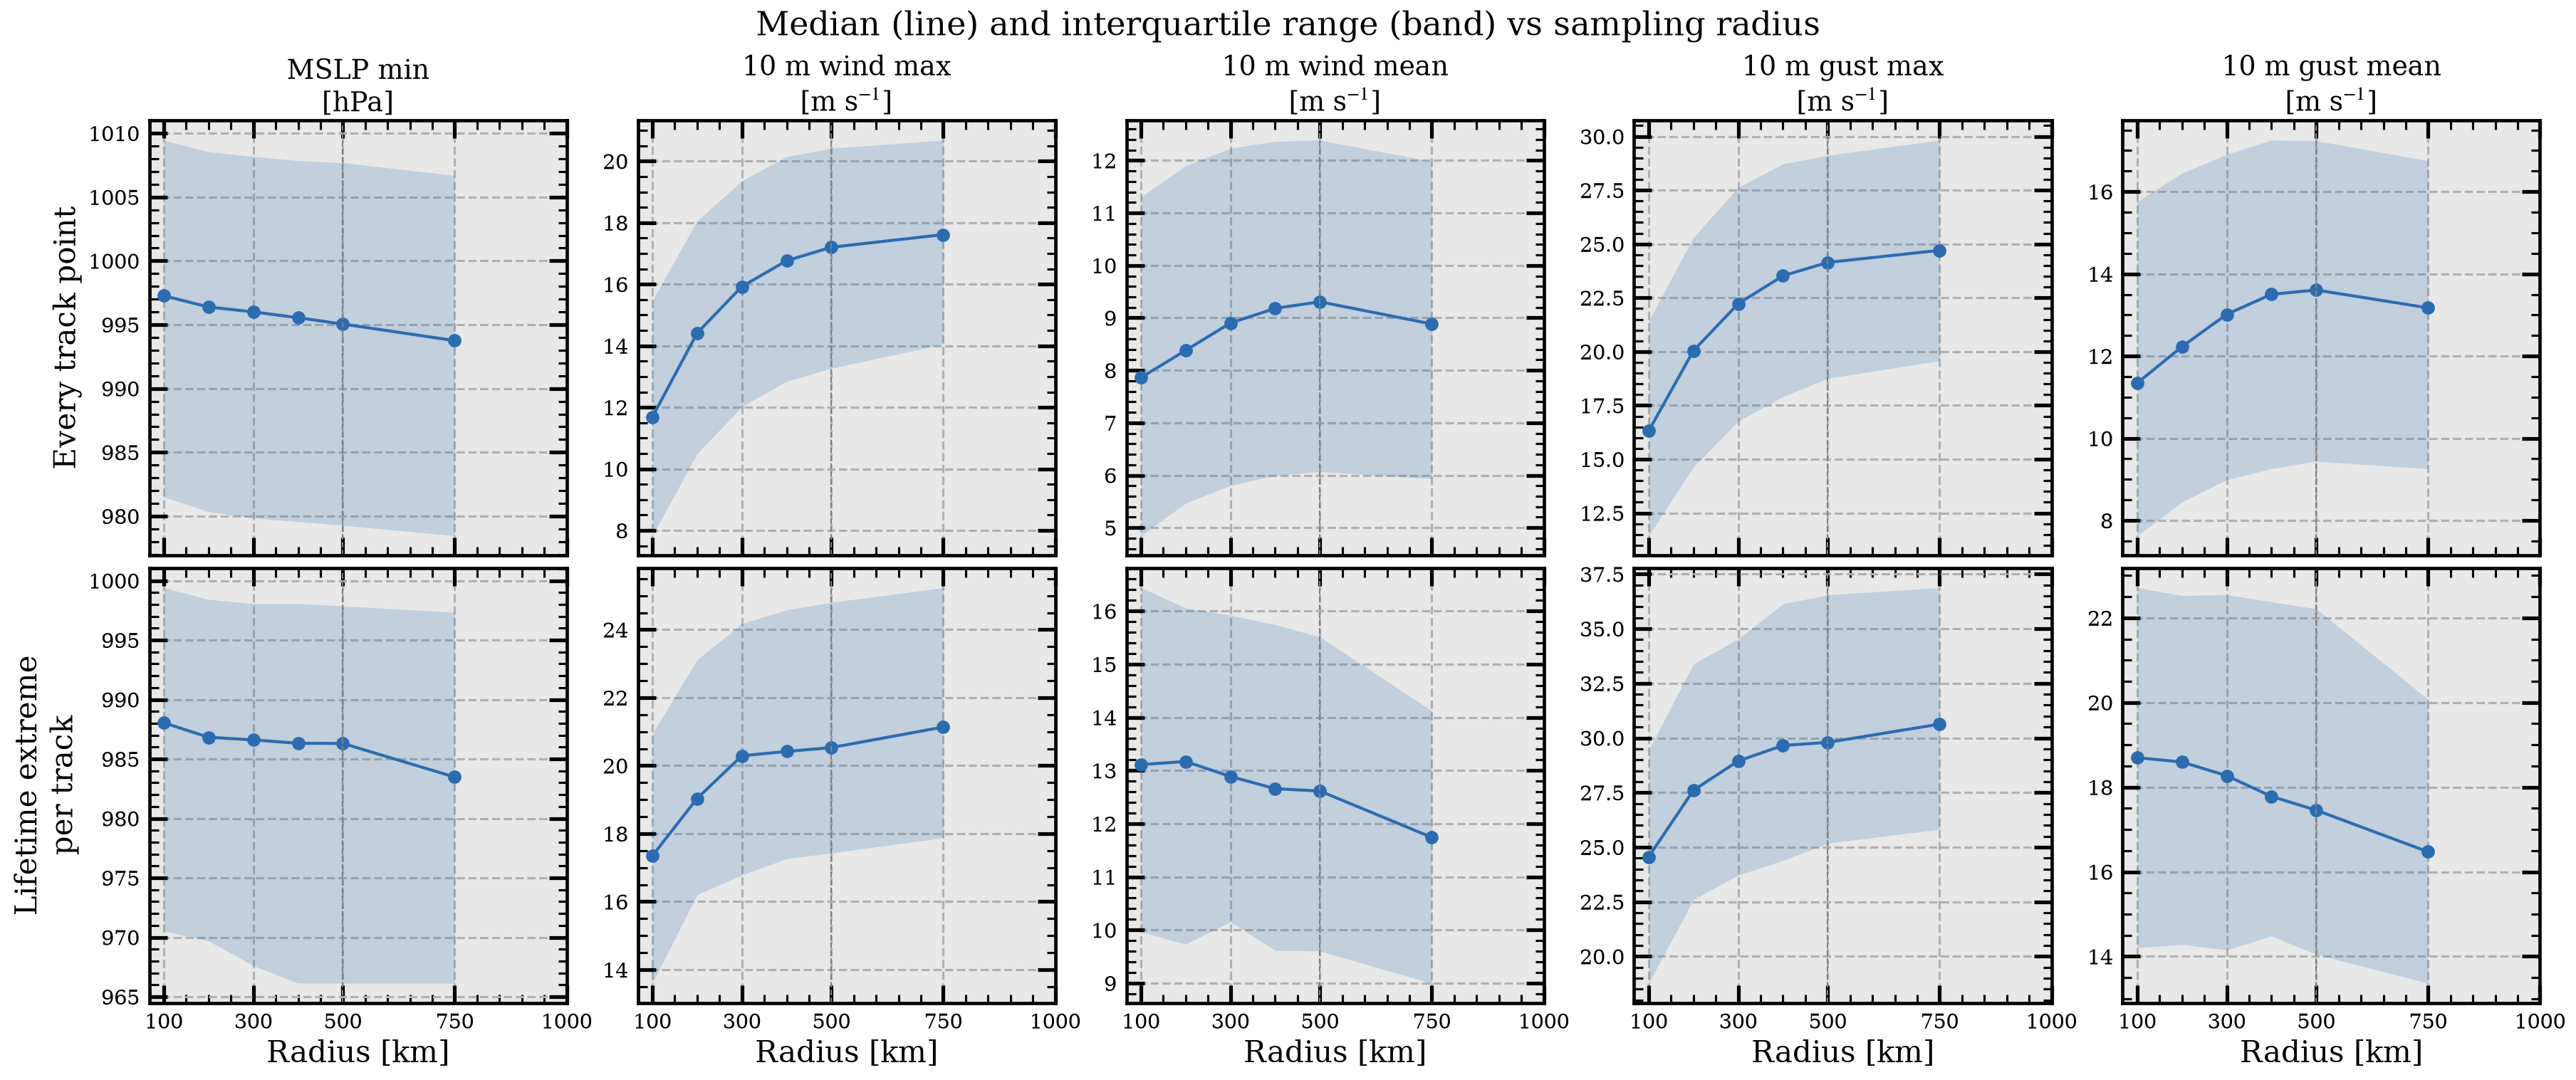

In [7]:
def median_iqr(ax, df, col):
    q = df.groupby("radius_km")[col].quantile([0.25, 0.5, 0.75]).unstack()
    ax.fill_between(q.index, q[0.25], q[0.75], color=LINE, alpha=0.2, lw=0)
    ax.plot(q.index, q[0.5], color=LINE, lw=2, marker="o", ms=8)

fig, axes = plt.subplots(2, len(VARS), figsize=(24, 10), sharex=True, constrained_layout=True)
for j, (col, (label, unit, agg)) in enumerate(VARS.items()):
    median_iqr(axes[0, j], sampled, col)
    median_iqr(axes[1, j], per_track, col)
    axes[0, j].set_title(f"{label}\n[{unit}]", fontsize=18)
    for ax in axes[:, j]:
        ax.axvline(REF_RADIUS, color="0.5", lw=1, ls="--")
        ax.set_xticks([100, 300, 500, 750, 1000])
        plain_axis(ax, "y"); plain_axis(ax, "x")
    axes[1, j].set_xlabel("Radius [km]")
axes[0, 0].set_ylabel("Every track point")
axes[1, 0].set_ylabel("Lifetime extreme\nper track")
fig.suptitle("Median (line) and interquartile range (band) vs sampling radius", fontsize=22)
plt.show()

### Distribution at each radius (all track points)

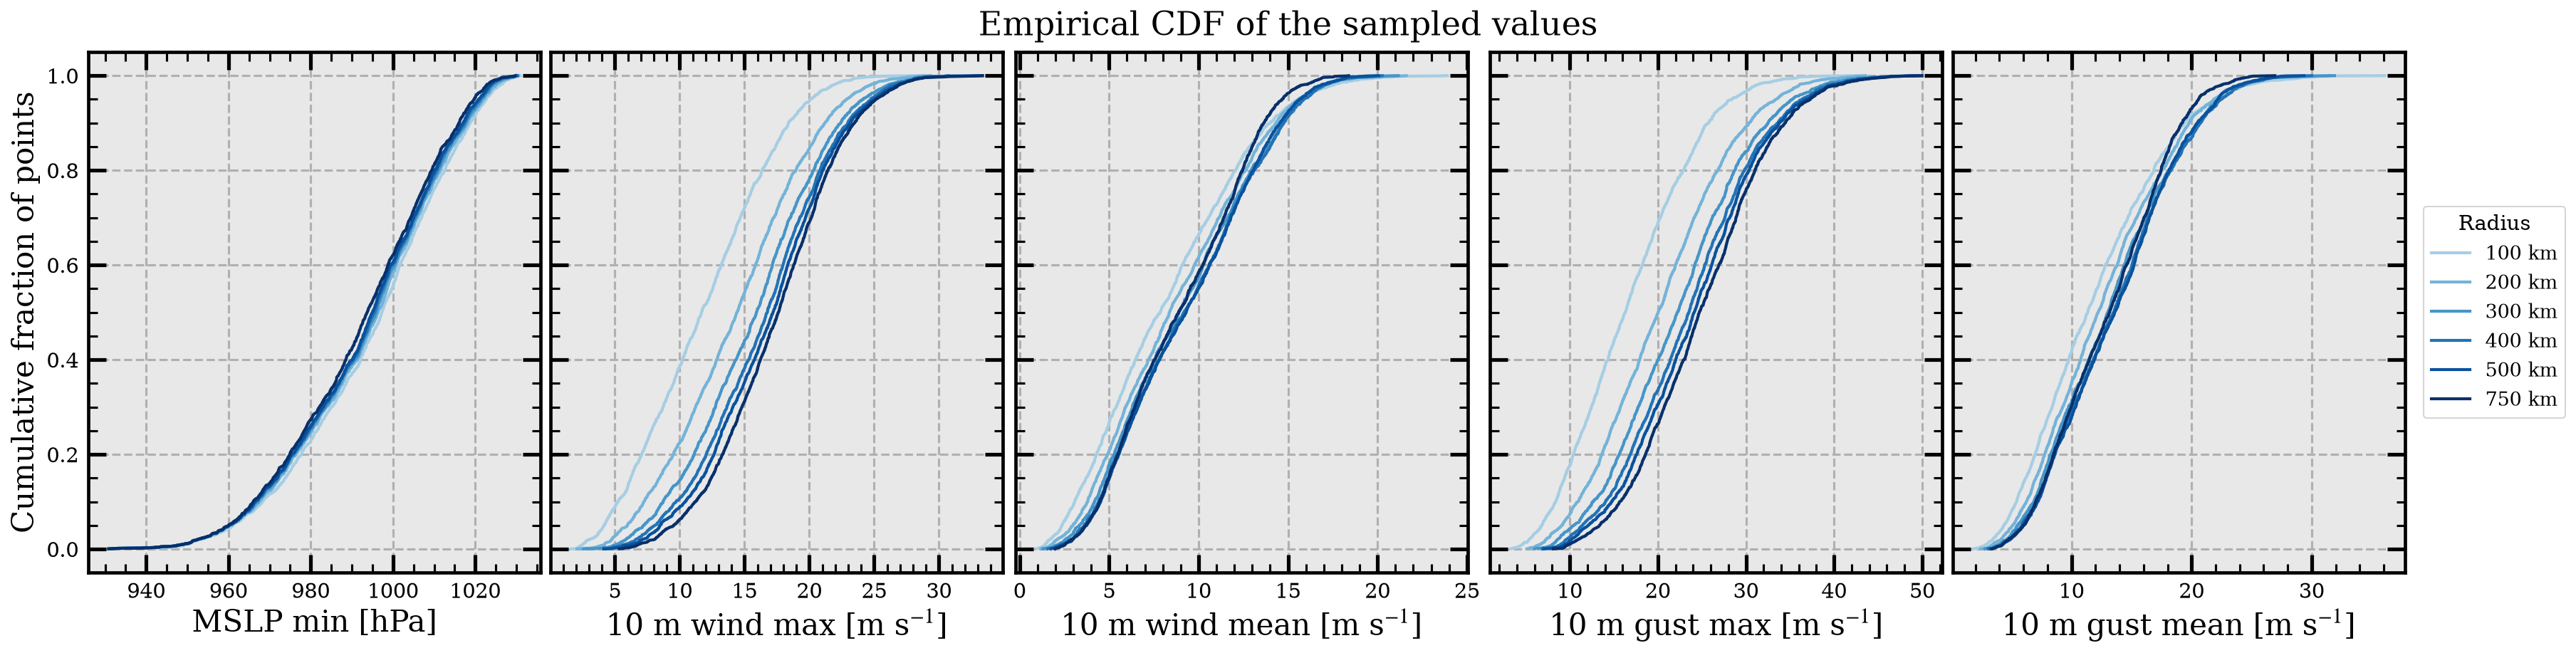

In [8]:
fig, axes = plt.subplots(1, len(VARS), figsize=(24, 6), sharey=True, constrained_layout=True)
for ax, (col, (label, unit, _)) in zip(axes, VARS.items()):
    for r in RADII:
        x = np.sort(sampled.loc[sampled["radius_km"] == r, col].dropna())
        ax.plot(x, np.arange(1, len(x) + 1) / len(x), color=RCOL[r], lw=2, label=f"{r} km")
    ax.set_xlabel(f"{label} [{unit}]")
    plain_axis(ax, "x")
axes[0].set_ylabel("Cumulative fraction of points")
legend_outside(axes[-1])
fig.suptitle("Empirical CDF of the sampled values", fontsize=22)
plt.show()

### One track through its life
Change `track_id` to look at another storm (default: the deepest track at `REF_RADIUS`).

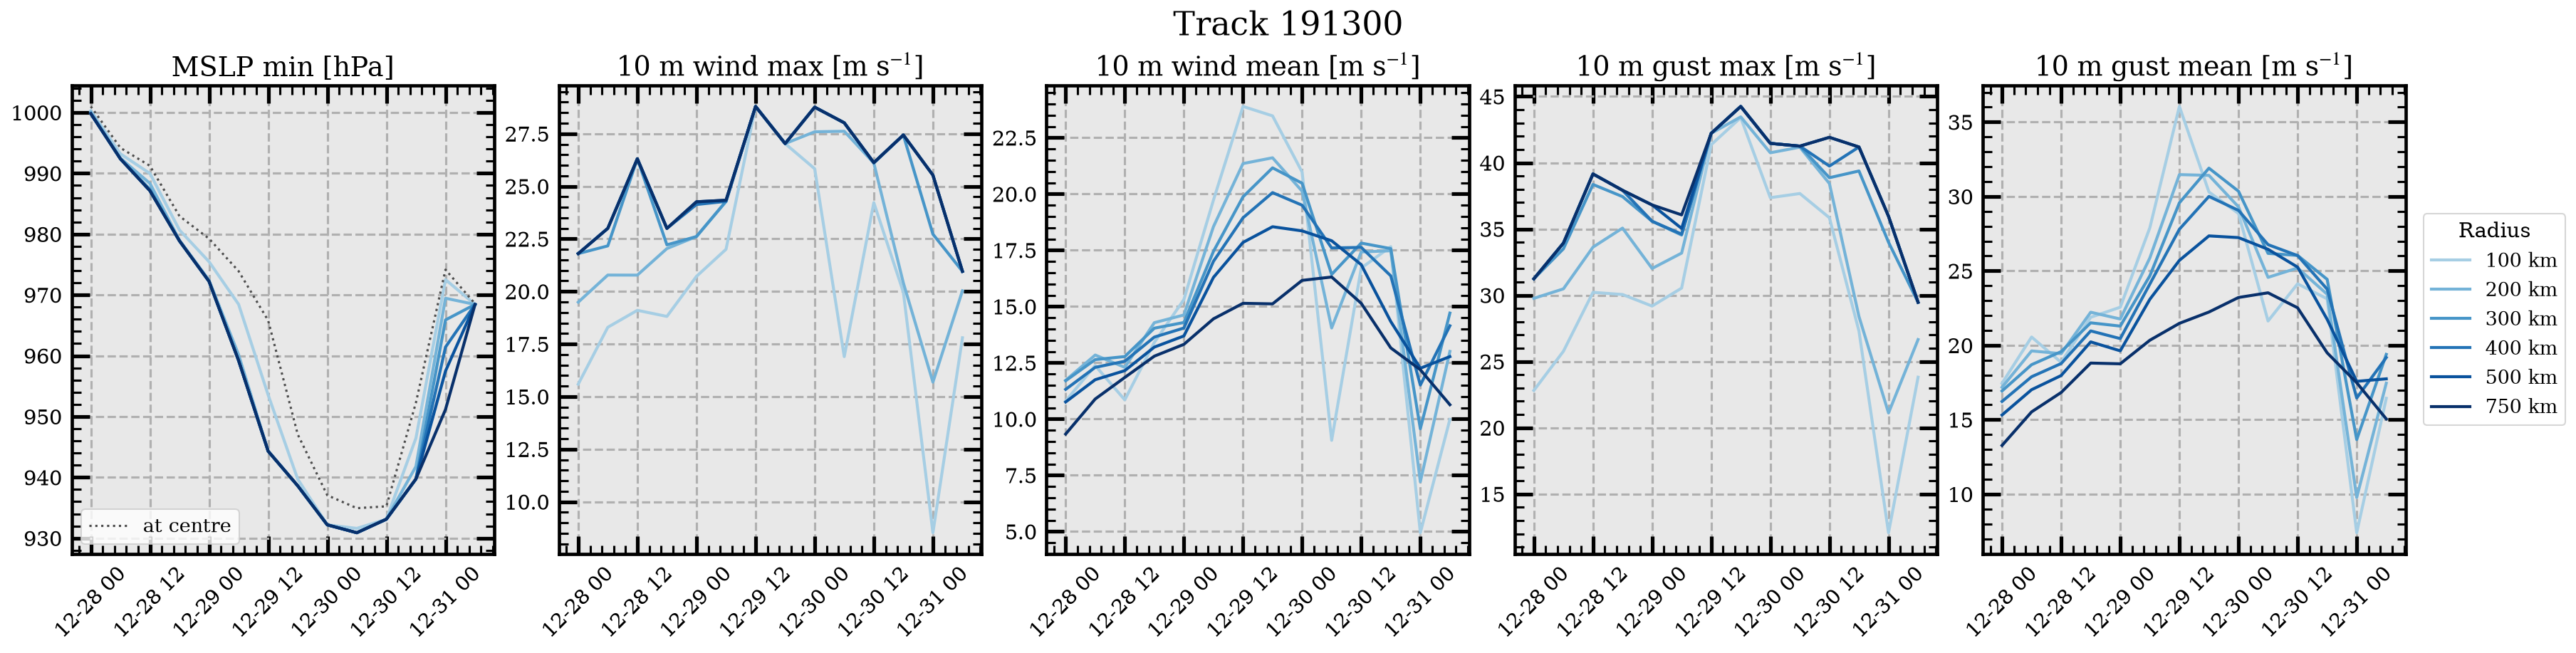

In [9]:
track_id = per_track.loc[per_track["radius_km"] == REF_RADIUS].nsmallest(1, "msl_min")["track_id"].iloc[0]
one = sampled[sampled["track_id"] == track_id]

fig, axes = plt.subplots(1, len(VARS), figsize=(24, 6), sharex=True, constrained_layout=True)
for ax, (col, (label, unit, _)) in zip(axes, VARS.items()):
    for r in RADII:
        d = one[one["radius_km"] == r]
        ax.plot(d["time"], d[col], color=RCOL[r], lw=2, label=f"{r} km")
    if col == "msl_min":   # pressure at the vorticity centre does not depend on the radius
        d = one[one["radius_km"] == REF_RADIUS]
        ax.plot(d["time"], d["msl_center"], color="0.3", lw=1.5, ls=":", label="at centre")
        ax.legend(handles=ax.lines[-1:], fontsize=13, loc="lower left")
        plain_axis(ax, "y")
    ax.set_title(f"{label} [{unit}]", fontsize=18)
    ax.tick_params(axis="x", labelrotation=45)
legend_outside(axes[-1])
fig.suptitle(f"Track {track_id}", fontsize=22)
plt.show()

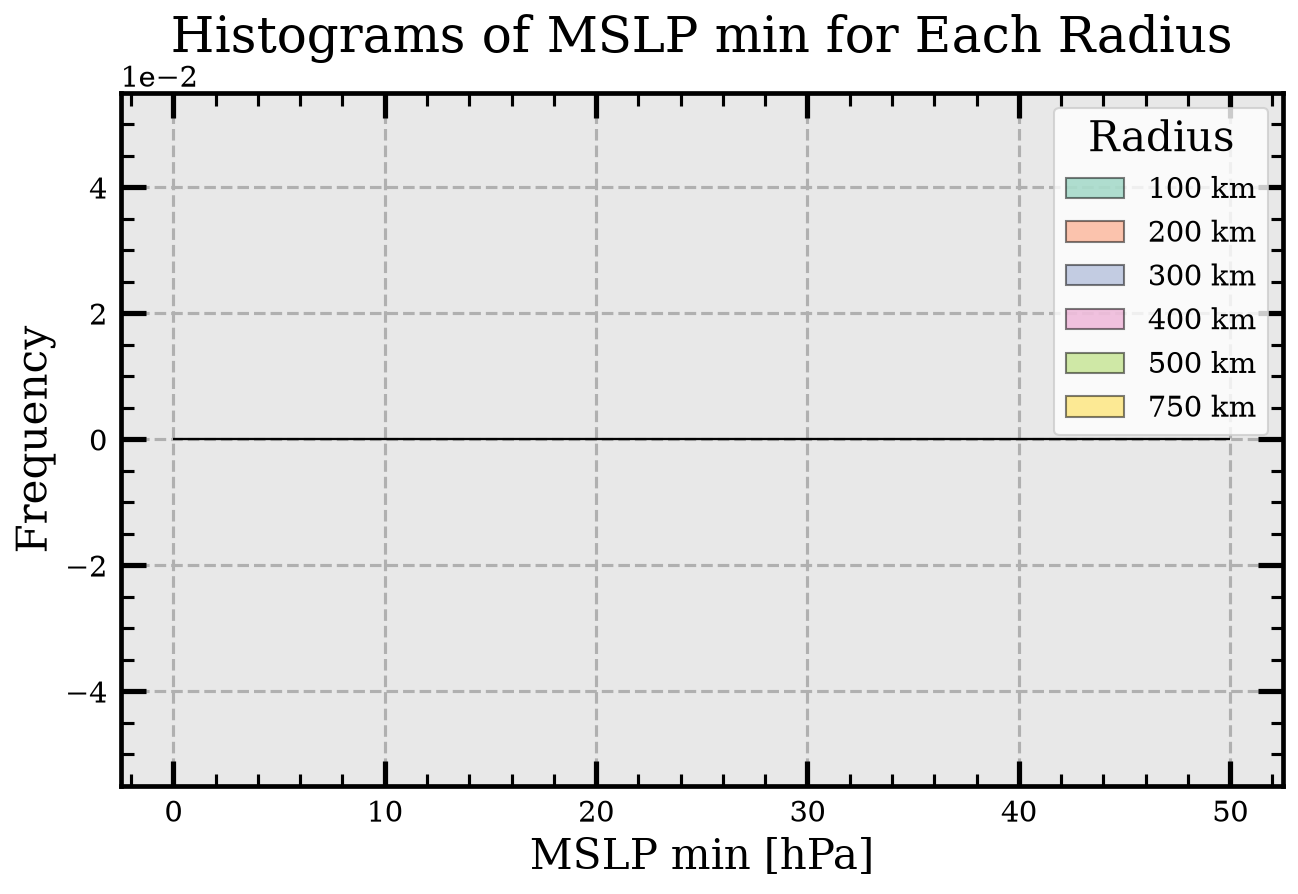

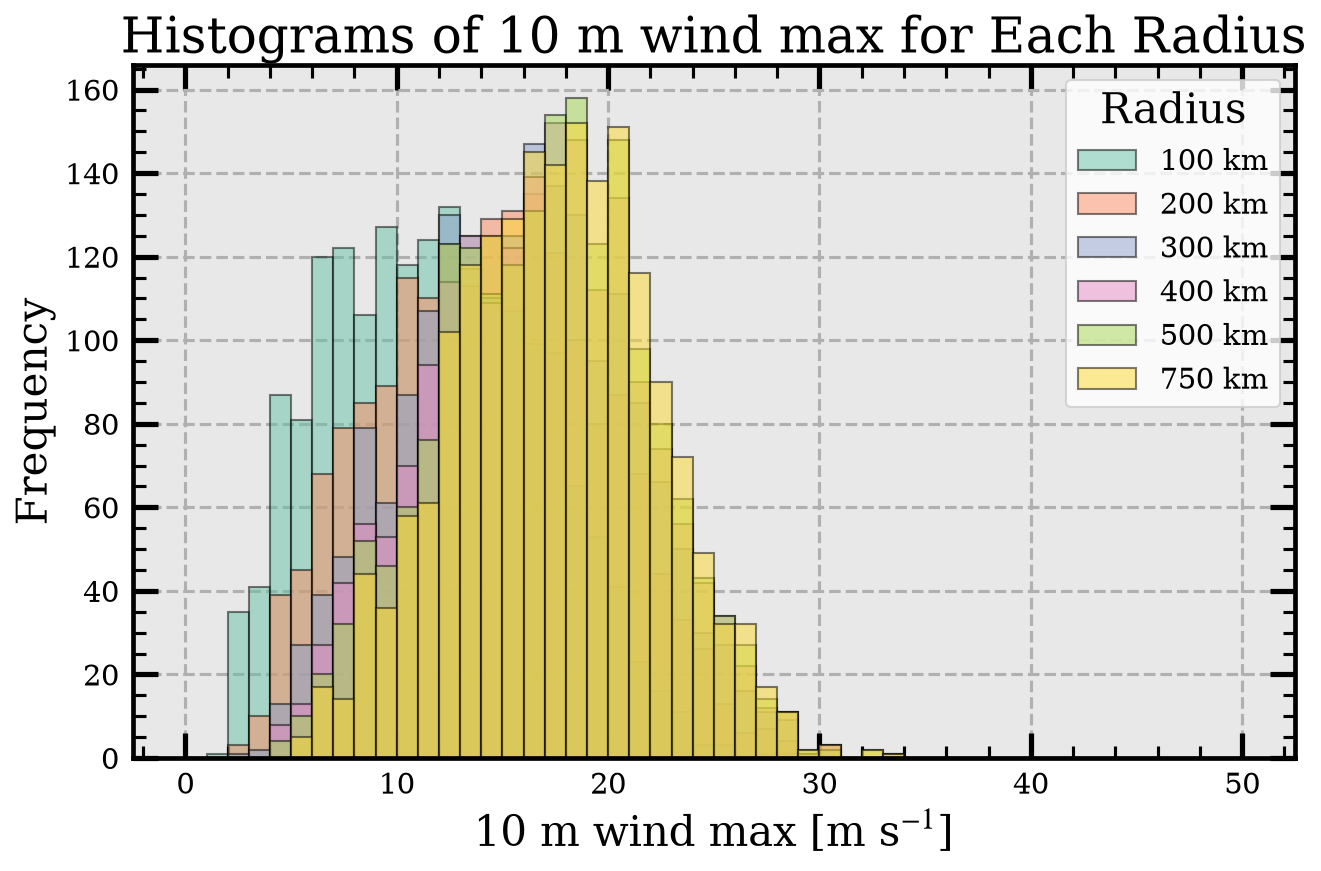

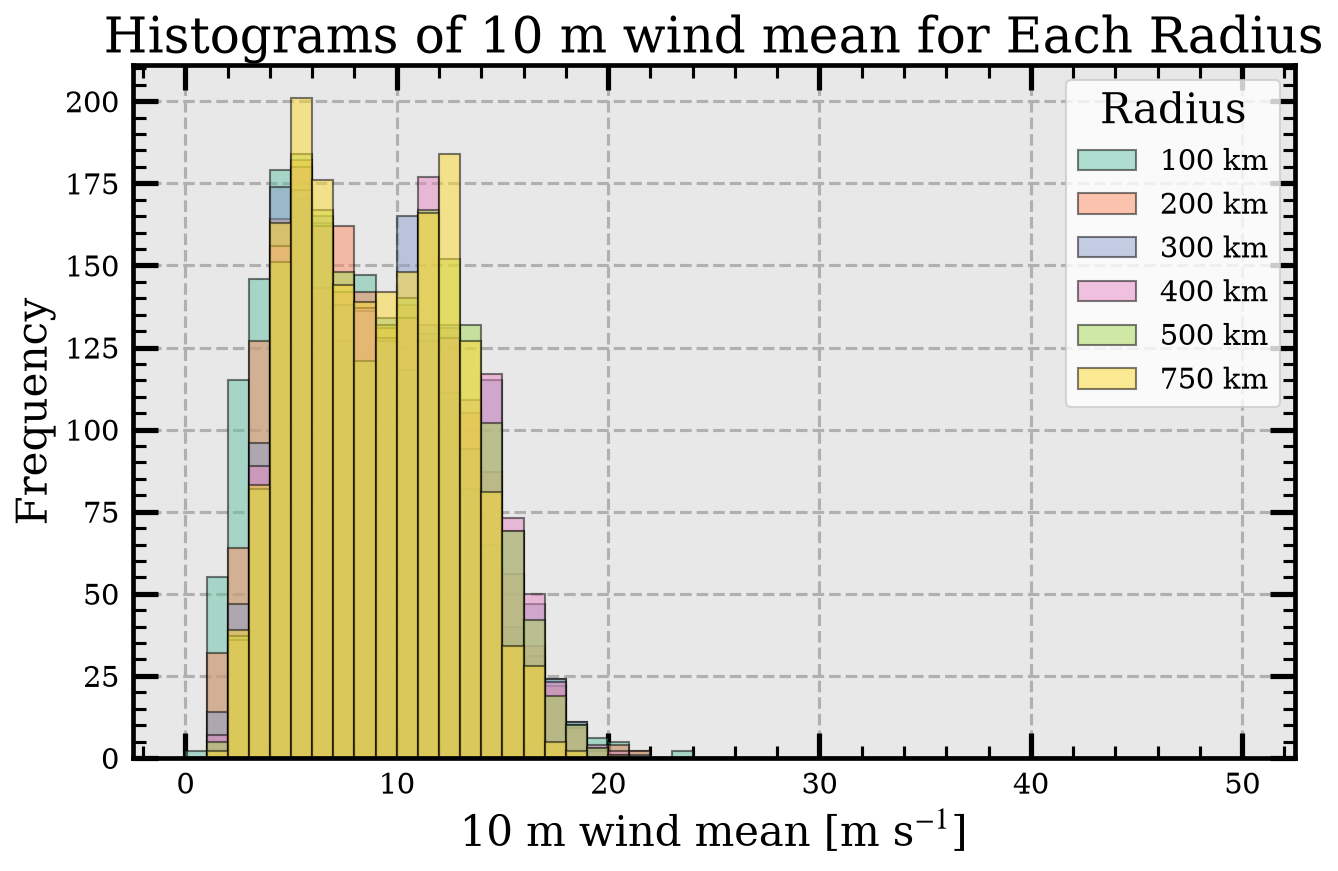

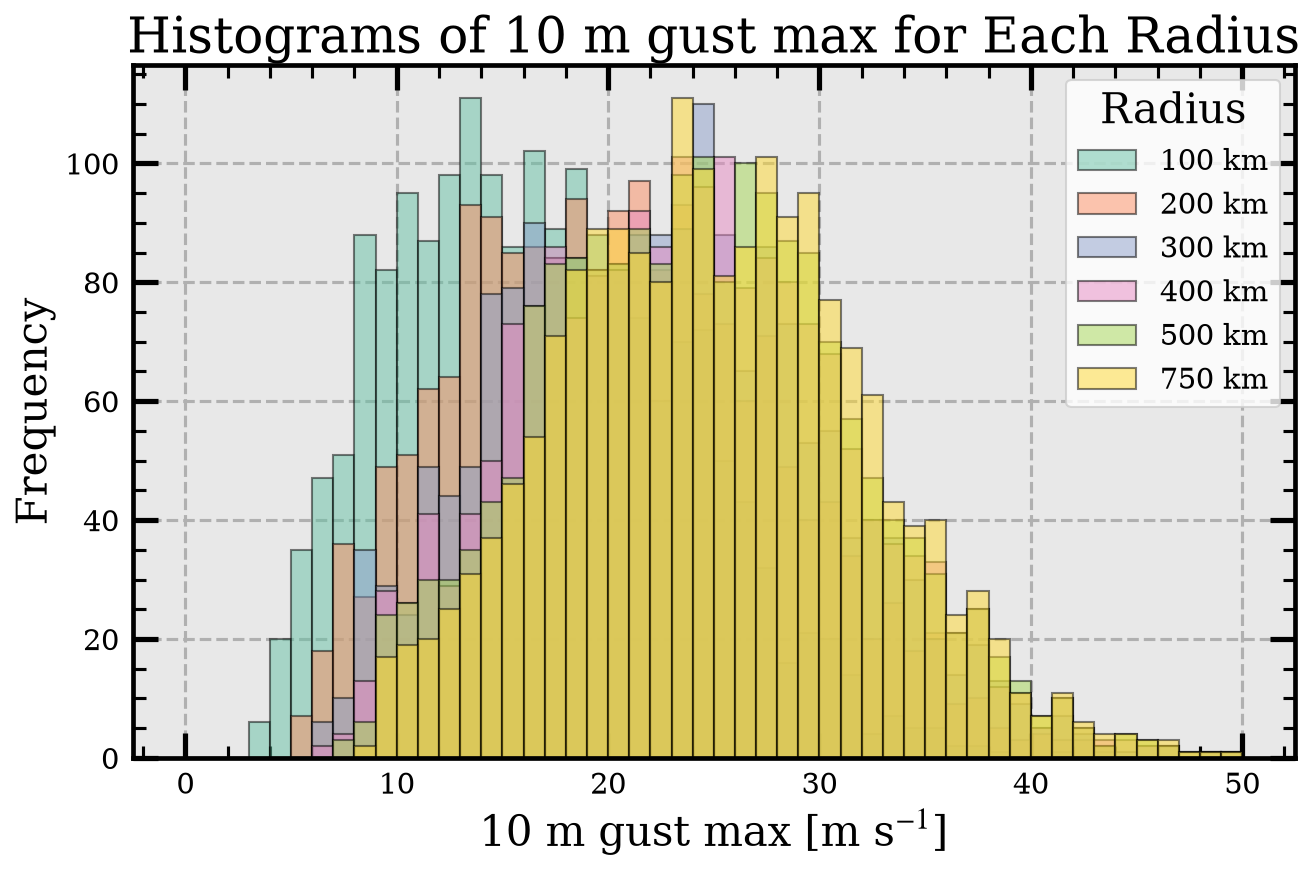

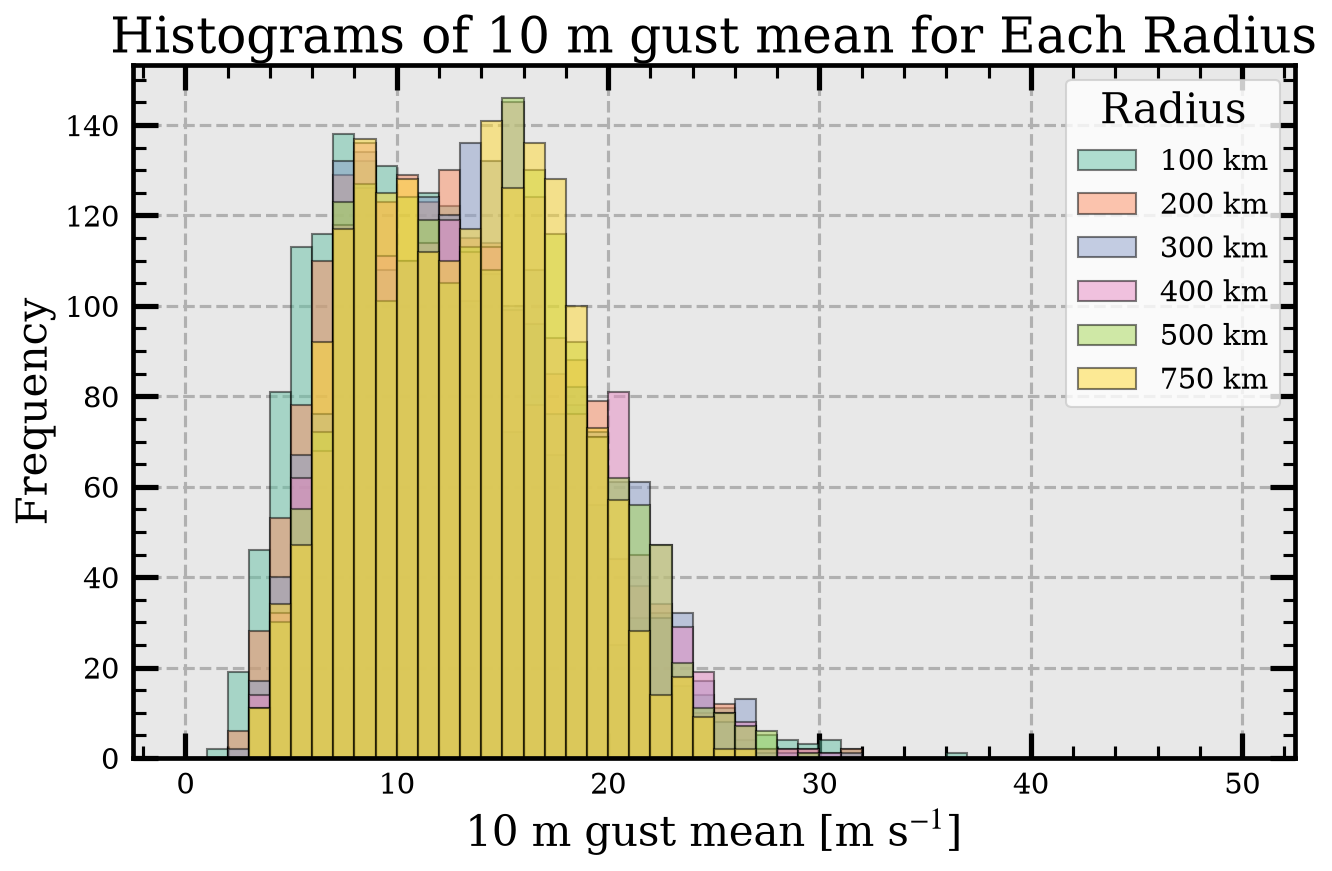

In [10]:
bin_width = 1.0
bin_edges = np.arange(0, 50 + bin_width, bin_width)

for col, (label, unit, _) in VARS.items():
    plt.figure(figsize=(10, 6))
    for r in RADII:
        plt.hist(sampled[sampled["radius_km"] == r][col].dropna(), bins=bin_edges, alpha=0.5, label=f"{r} km", edgecolor='k')
    plt.xlabel(f"{label} [{unit}]")
    plt.ylabel("Frequency")
    plt.legend(title="Radius")
    plt.title(f"Histograms of {label} for Each Radius")
    plt.show()

#for r in RADII[4:]:
#    plt.hist(sampled[sampled["radius_km"] == r]["ws10_max"].dropna(), bins=30, alpha=0.5, label=f"{r} km", edgecolor= 'k')
#plt.xlabel("Wind Speed max [m s$^{-1}$]")
#plt.ylabel("Frequency")
#plt.legend(title="Radius")
#plt.title("Histograms of Wind Speeds for Each Radius")
#plt.show()